**CAD-ViT: Coordinate Attention-Enhanced Vision Transformer With Dilated Feature Fusion for Diabetic Retinopathy Staging**

Original Paper: https://ieeexplore.ieee.org/document/11009024

**Dataset Used**

- APTOS 2019
https://www.kaggle.com/datasets/mariaherrerot/aptos2019

- DDR
https://www.kaggle.com/datasets/mariaherrerot/ddrdataset

## 1. Siapkan Library

In [20]:
from google.colab import userdata, drive
import os
import kagglehub
import shutil
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from IPython.display import display

## 2. Dataset Acquisition &amp; Partitioning

In [16]:
# Kaggle authentication
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Mount Google Drive
drive.mount("/content/drive")

# Persistent dataset directory
DRIVE_ROOT = "/content/drive/MyDrive/CAD_ViT"
DATA_DIR = os.path.join(DRIVE_ROOT, "datasets")

os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset directory:", DATA_DIR)
print("Existing folders:", os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset directory: /content/drive/MyDrive/CAD_ViT/datasets
Existing folders: ['DDR', 'APTOS']


In [10]:
APTOS_DIR = os.path.join(DATA_DIR, "APTOS")
os.makedirs(APTOS_DIR, exist_ok=True)

path_aptos = kagglehub.dataset_download(
    "mariaherrerot/aptos2019",
    output_dir=APTOS_DIR
)

print("APTOS path:", path_aptos)

Using Colab cache for faster access to the 'aptos2019' dataset.
APTOS path: /kaggle/input/aptos2019


In [11]:
DDR_DIR = os.path.join(DATA_DIR, "DDR")
os.makedirs(DDR_DIR, exist_ok=True)

path_ddr = kagglehub.dataset_download(
    "mariaherrerot/ddrdataset",
    output_dir=DDR_DIR
)

print("DDR path:", path_ddr)

Using Colab cache for faster access to the 'ddrdataset' dataset.
DDR path: /kaggle/input/ddrdataset


In [17]:
shutil.copytree(path_aptos, APTOS_DIR, dirs_exist_ok=True)
shutil.copytree(path_ddr,DDR_DIR,dirs_exist_ok=True)

'/content/drive/MyDrive/CAD_ViT/datasets/DDR'

## 2. Exploratory Data Analysis (EDA)



1.   Dataset structure : Folder, CSV, jumlah image, dan format file
2.   Label analysis    : Distribusi lima tingkat diabetic retinopathy
1.   Image inspection  : Dimensi, mode warna, dan visualisasi sampel
2.   Data quality : Missing files, label tidak valid, dan duplikasi
1.   EDA summary : Kesimpulan untuk preprocessing dan splitting







In [26]:
ImageFile.LOAD_TRUNCATED_IMAGES = False

DATASETS = {
    "APTOS": DATA_DIR / "APTOS",
    "DDR": DATA_DIR / "DDR",
}

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

DR_LABELS = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}

for name, path in DATASETS.items():
    assert path.is_dir(), f"{name} directory not found: {path}"
    print(f"{name}: {path}")

print("\nSetup completed.")

APTOS: /content/drive/MyDrive/CAD_ViT/datasets/APTOS
DDR: /content/drive/MyDrive/CAD_ViT/datasets/DDR

Setup completed.


In [35]:
# Dataset Structure
summary_rows = []
csv_rows = []

for dataset_name, root in DATASETS.items():
    root = Path(root)
    format_counts = Counter()
    folder_counts = Counter()
    csv_files = []

    for file_path in root.rglob("*"):
        if not file_path.is_file():
            continue

        ext = file_path.suffix.lower()

        if ext in IMAGE_EXTENSIONS:
            format_counts[ext] += 1
            rel_parts = file_path.relative_to(root).parts
            folder_counts[rel_parts[0] if len(rel_parts) > 1 else "(root)"] += 1
        elif ext == ".csv":
            csv_files.append(file_path)

    # One row per dataset
    summary_rows.append({
        "dataset": dataset_name,
        "images": sum(format_counts.values()),
        "formats": dict(format_counts),
        "top_level_folders": len(folder_counts),
        "csv_files": len(csv_files),
    })

    print(f"\n=== {dataset_name} ===")
    print(pd.Series(folder_counts, name="images").sort_index().to_frame().T.to_string())

    for csv_path in csv_files:
        try:
            df = pd.read_csv(csv_path)
            csv_rows.append({
                "dataset": dataset_name,
                "csv": str(csv_path.relative_to(root)),
                "rows": len(df),
                "columns": df.columns.tolist(),
            })
        except Exception as e:
            csv_rows.append({
                "dataset": dataset_name,
                "csv": str(csv_path.relative_to(root)),
                "rows": None,
                "columns": f"ERROR: {e}",
            })

structure_df = pd.DataFrame(summary_rows)
csv_df = pd.DataFrame(csv_rows)

print("\n--- DATASET SUMMARY ---")
display(structure_df)

if not csv_df.empty:
    print("\n--- CSV SUMMARY ---")
    display(csv_df)


=== APTOS ===
        test_images  train_images  val_images
images          366          2930         366

=== DDR ===
        DR_grading
images       12524

--- DATASET SUMMARY ---


,dataset,images,formats,top_level_folders,csv_files
0,APTOS,3662,{'.png': 3662},3,3
1,DDR,12524,{'.jpg': 12524},1,1



--- CSV SUMMARY ---


,dataset,csv,rows,columns
0,APTOS,valid.csv,366,"[id_code, diagnosis]"
1,APTOS,test.csv,366,"[id_code, diagnosis]"
2,APTOS,train_1.csv,2930,"[id_code, diagnosis]"
3,DDR,DR_grading.csv,12522,"[id_code, diagnosis]"


In [45]:
def inspect_images(dataset_name):
    root = DATASETS[dataset_name]

    image_paths = [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]

    records = []

    for i, path in enumerate(image_paths, start=1):
        try:
            with Image.open(path) as img:
                records.append({
                    "path": str(path),
                    "filename": path.name,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format,
                    "valid": True,
                    "error": None,
                })
        except Exception as e:
            records.append({"path": str(path),"filename": path.name,"width": None,
                "height": None,"mode": None,"format": None,"valid": False,"error": str(e),
            })
    return pd.DataFrame(records)

image_metadata = {}
for name in DATASETS:
    print(f"\nInspecting {name}...")
    image_metadata[name] = inspect_images(name)
    meta = image_metadata[name]

    print("Total files:", len(meta))
    print("Readable images:", meta["valid"].sum())
    print("Unreadable images:", (~meta["valid"]).sum())

    print("\nImage dimensions:")
    display(meta.loc[meta["valid"], ["width", "height"]].describe())

    print("\nColor modes:")
    display(meta["mode"].value_counts(dropna=False).to_frame("count"))

    print("\nImage formats:")
    display(meta["format"].value_counts(dropna=False).to_frame("count"))


Inspecting APTOS...
Total files: 3662
Readable images: 3662
Unreadable images: 0

Image dimensions:


,width,height
count,3662.000000,3662.000000
mean,2015.176679,1526.830147
std,884.301940,542.663120
min,474.000000,358.000000
25%,1050.000000,1050.000000
50%,2144.000000,1536.000000
75%,2588.000000,1958.000000
max,4288.000000,2848.000000



Color modes:


,count
mode,
RGB,3662



Image formats:


...

,width,height
count,12524.000000,12524.000000
mean,811.844379,733.075295
std,717.548192,537.970596
min,512.000000,512.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,5184.000000,3456.000000



Color modes:


,count
mode,
RGB,12524



Image formats:


,count
format,
JPEG,12405
MPO,119


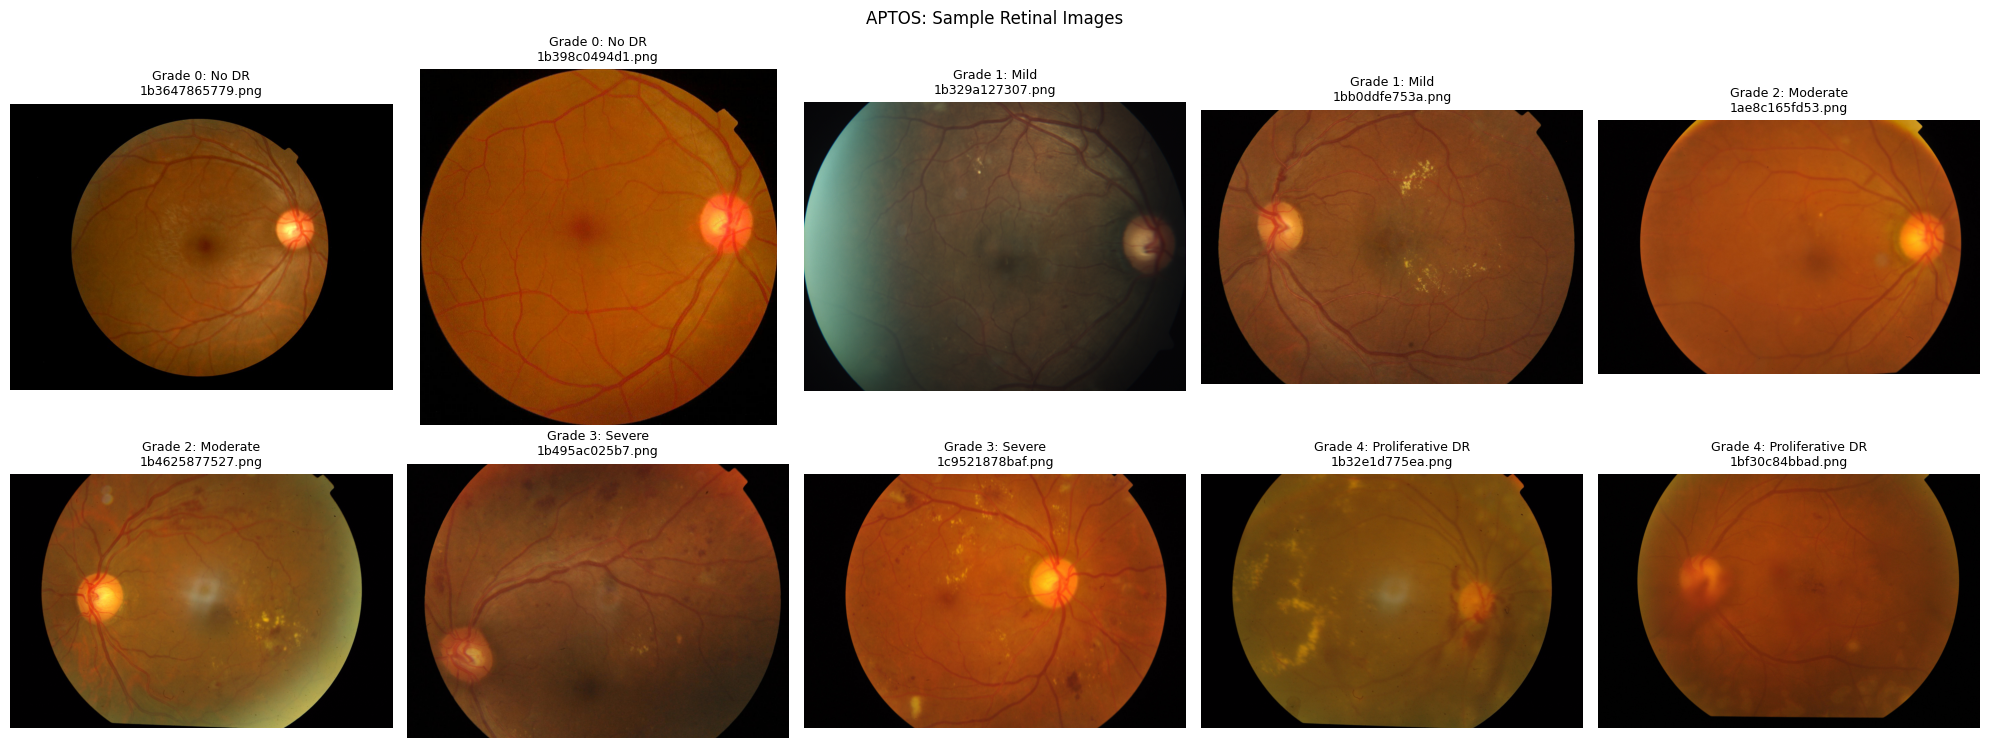

DDR: annotations belum tersedia.


In [44]:
def visualize_class_samples(dataset_name, samples_per_class=2):
    df = annotations.get(dataset_name)
    cfg = LABEL_CONFIG[dataset_name]

    if df is None:
        print(f"{dataset_name}: annotations belum tersedia.")
        return

    image_col = cfg["image_column"]
    label_col = cfg["label_column"]
    root = DATASETS[dataset_name]
    image_map = {}

    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            image_map.setdefault(p.stem, p)

    label_values = pd.to_numeric(df[label_col], errors="coerce")
    df_work = df.copy()
    df_work["_label"] = label_values

    selected = []

    for grade in range(5):
        candidates = df_work[df_work["_label"] == grade]

        found = 0
        for _, row in candidates.iterrows():
            image_id = str(row[image_col]).strip()
            stem = Path(image_id).stem

            if stem in image_map:
                selected.append((grade, image_map[stem]))
                found += 1

            if found >= samples_per_class:
                break

        if found == 0:
            print(
                f"Grade {grade}: no matching images found. "
                "Check the image ID column and folder structure."
            )

    if not selected:
        print("No matching images found.")
        return

    ncols = min(5, len(selected))
    nrows = int(np.ceil(len(selected) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4 * ncols, 4 * nrows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (grade, path) in zip(axes.flat, selected):
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"Grade {grade}: {DR_LABELS[grade]}\n{path.name}",
                fontsize=9
            )
            ax.axis("off")
        except Exception as e:
            ax.set_title(f"Error: {path.name}")
            print(f"Cannot display {path}: {e}")

    plt.suptitle(f"{dataset_name}: Sample Retinal Images")
    plt.tight_layout()
    plt.show()


for name in DATASETS:
    visualize_class_samples(name, samples_per_class=2)

## 3. Preprocessing, Resampling, and Augmentation

## 4. CAD-ViT model

## 5. Training

## 6. Evaluation
Compute accuracy, precision, recall, F1-score, and specificity